### **_`Import Libraries`_**


In [136]:
## Base Imports
import os
import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## set the plt background as a dark_background
plt.style.use("dark_background")

## Import Processing Operations
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

## Import models
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

## Import evaluation metric
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Hyperparameters Tuning
from sklearn.model_selection import GridSearchCV

### **_`Load The DataSet`_**


In [137]:
## get the main path of the project directory
MAIN_PATH = os.getcwd()

## get the path of the data set
DATA_PATH = os.path.join(MAIN_PATH, "..", "data", "data.csv")

In [138]:
## load the dataset
df = pd.read_csv(DATA_PATH)

In [139]:
## displaying the first 5 rows of the data
df.head()

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,2014-05-02 00:00:00,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,2014-05-02 00:00:00,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,2014-05-02 00:00:00,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,2014-05-02 00:00:00,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA


In [140]:
## display features
df.columns

Index(['date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot',
       'floors', 'waterfront', 'view', 'condition', 'sqft_above',
       'sqft_basement', 'yr_built', 'yr_renovated', 'street', 'city',
       'statezip', 'country'],
      dtype='str')

In [141]:
## get some info about the dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           4600 non-null   str    
 1   price          4600 non-null   float64
 2   bedrooms       4600 non-null   float64
 3   bathrooms      4600 non-null   float64
 4   sqft_living    4600 non-null   int64  
 5   sqft_lot       4600 non-null   int64  
 6   floors         4600 non-null   float64
 7   waterfront     4600 non-null   int64  
 8   view           4600 non-null   int64  
 9   condition      4600 non-null   int64  
 10  sqft_above     4600 non-null   int64  
 11  sqft_basement  4600 non-null   int64  
 12  yr_built       4600 non-null   int64  
 13  yr_renovated   4600 non-null   int64  
 14  street         4600 non-null   str    
 15  city           4600 non-null   str    
 16  statezip       4600 non-null   str    
 17  country        4600 non-null   str    
dtypes: float64(4), int6

In [142]:
df.describe()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated
count,4.600000e+03,4600.000000,4600.000000,4600.000000,4.600000e+03,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000
mean,5.519630e+05,3.400870,2.160815,2139.346957,1.485252e+04,1.512065,0.007174,0.240652,3.451739,1827.265435,312.081522,1970.786304,808.608261
std,5.638347e+05,0.908848,0.783781,963.206916,3.588444e+04,0.538288,0.084404,0.778405,0.677230,862.168977,464.137228,29.731848,979.414536
min,0.000000e+00,0.000000,0.000000,370.000000,6.380000e+02,1.000000,0.000000,0.000000,1.000000,370.000000,0.000000,1900.000000,0.000000
25%,3.228750e+05,3.000000,1.750000,1460.000000,5.000750e+03,1.000000,0.000000,0.000000,3.000000,1190.000000,0.000000,1951.000000,0.000000
50%,4.609435e+05,3.000000,2.250000,1980.000000,7.683000e+03,1.500000,0.000000,0.000000,3.000000,1590.000000,0.000000,1976.000000,0.000000
75%,6.549625e+05,4.000000,2.500000,2620.000000,1.100125e+04,2.000000,0.000000,0.000000,4.000000,2300.000000,610.000000,1997.000000,1999.000000
max,2.659000e+07,9.000000,8.000000,13540.000000,1.074218e+06,3.500000,1.000000,4.000000,5.000000,9410.000000,4820.000000,2014.000000,2014.000000


In [143]:
"""
# there are some houses that have a price with 0
# we will try to remove these values from the target data
# to make sure that no thing will distracts
"""

'\n# there are some houses that have a price with 0\n# we will try to remove these values from the target data\n# to make sure that no thing will distracts\n'

In [144]:
df["price"].describe()

count    4.600000e+03
mean     5.519630e+05
std      5.638347e+05
min      0.000000e+00
25%      3.228750e+05
50%      4.609435e+05
75%      6.549625e+05
max      2.659000e+07
Name: price, dtype: float64

In [145]:
df = df[df["price"] > 10000]

In [146]:
df["price"].describe()

count    4.550000e+03
mean     5.580268e+05
std      5.639329e+05
min      8.000000e+04
25%      3.264464e+05
50%      4.650000e+05
75%      6.575000e+05
max      2.659000e+07
Name: price, dtype: float64

In [147]:
"""
## The most important notes about the dataset
    1. the total number of Features (Columns) -> 18
    2. the total number of records (Rows) -> 4600
    3. There is no missing values in the dataset (No Nans)
    4. Categorical (Discreat) Features ['date', 'street', 'city', 'statezip', 'country']
    5. Others are Numirical (Continuous) Features
"""

"\n## The most important notes about the dataset\n    1. the total number of Features (Columns) -> 18\n    2. the total number of records (Rows) -> 4600\n    3. There is no missing values in the dataset (No Nans)\n    4. Categorical (Discreat) Features ['date', 'street', 'city', 'statezip', 'country']\n    5. Others are Numirical (Continuous) Features\n"

## 📊 Dataset Features Description

This dataset contains information about houses, including their prices, sizes, locations, and conditions. Each feature provides useful information that can help us understand and predict house prices.

### Feature Descriptions

| Feature         | Description                                | Benefit                                        |
| :-------------- | :----------------------------------------- | :--------------------------------------------- |
| `date`          | Date the house was recorded.               | Helps analyze price changes over time.         |
| `price`         | Price of the house.                        | Represents the house's market value.           |
| `bedrooms`      | Number of bedrooms.                        | Helps evaluate the house size.                 |
| `bathrooms`     | Number of bathrooms.                       | Helps measure comfort and convenience.         |
| `sqft_living`   | Total indoor living area.                  | Shows how spacious the house is.               |
| `sqft_lot`      | Total land area.                           | Shows the size of the property.                |
| `floors`        | Number of floors.                          | Describes the house structure.                 |
| `waterfront`    | Indicates whether the house is near water. | Helps identify waterfront properties.          |
| `view`          | Quality of the house view.                 | Helps evaluate the attractiveness of the view. |
| `condition`     | Overall condition of the house.            | Helps assess the house's quality.              |
| `sqft_above`    | Living area above ground.                  | Measures usable space above ground.            |
| `sqft_basement` | Basement area.                             | Shows additional space below ground.           |
| `yr_built`      | Year the house was built.                  | Helps determine the house's age.               |
| `yr_renovated`  | Year the house was renovated.              | Shows whether the house has been updated.      |
| `street`        | Street address of the house.               | Identifies the street location.                |
| `city`          | City where the house is located.           | Helps compare prices across cities.            |
| `statezip`      | State and ZIP code.                        | Identifies the property's specific area.       |
| `country`       | Country where the house is located.        | Identifies the property's country.             |

### 🎯 Dataset Objective

The main objective is to understand how different house features affect house prices and use these features to build a **Machine Learning model that predicts house prices**.

**Target Variable:** `price`


### **_EDA_**


In [148]:
"""
## The first step is trying to take any benefit from date column
    like making it refering to the price of the house throw the time of the same year
"""

'\n## The first step is trying to take any benefit from date column\n    like making it refering to the price of the house throw the time of the same year\n'

In [149]:
df["date"].min(), df["date"].max()

('2014-05-02 00:00:00', '2014-07-10 00:00:00')

In [150]:
"""
## So in this case, we found all houses are boutgh in the same year
    , so we will divide our date column into (day, month), to check if
    there is any relation between the time of boughting the house and it's price
"""

"\n## So in this case, we found all houses are boutgh in the same year\n    , so we will divide our date column into (day, month), to check if\n    there is any relation between the time of boughting the house and it's price\n"

In [151]:
df_splited_date_column = df.copy()

In [152]:
## convert the date column into datetime
df_splited_date_column["date"] = pd.to_datetime(df_splited_date_column["date"])

## splite the column
df_splited_date_column["day"] = df_splited_date_column["date"].dt.day
df_splited_date_column["month"] = df_splited_date_column["date"].dt.month

## removing the date column
df_splited_date_column = df_splited_date_column.drop(columns="date", index=1)

In [153]:
## get some info about the new columns (day, month)

print(f"the min value of day -> {df_splited_date_column['day'].min()}")
print(f"the max value of day -> {df_splited_date_column['day'].max()}")
print(f"the min value of month -> {df_splited_date_column['month'].min()}")
print(f"the max value of month -> {df_splited_date_column['month'].max()}")


## display the unique values for each feature (day, month)
print(f"the unique values of day -> {df_splited_date_column['day'].unique()}")
print(f"the unique values of month -> {df_splited_date_column['month'].unique()}")

the min value of day -> 1
the max value of day -> 31
the min value of month -> 5
the max value of month -> 7
the unique values of day -> [ 2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25
 26 27 28 29 30 31  1]
the unique values of month -> [5 6 7]


In [154]:
"""
## now we will display the relation between new features (day, month) and try to
    show the relation between both of them and price feature (Target)
"""

'\n## now we will display the relation between new features (day, month) and try to\n    show the relation between both of them and price feature (Target)\n'

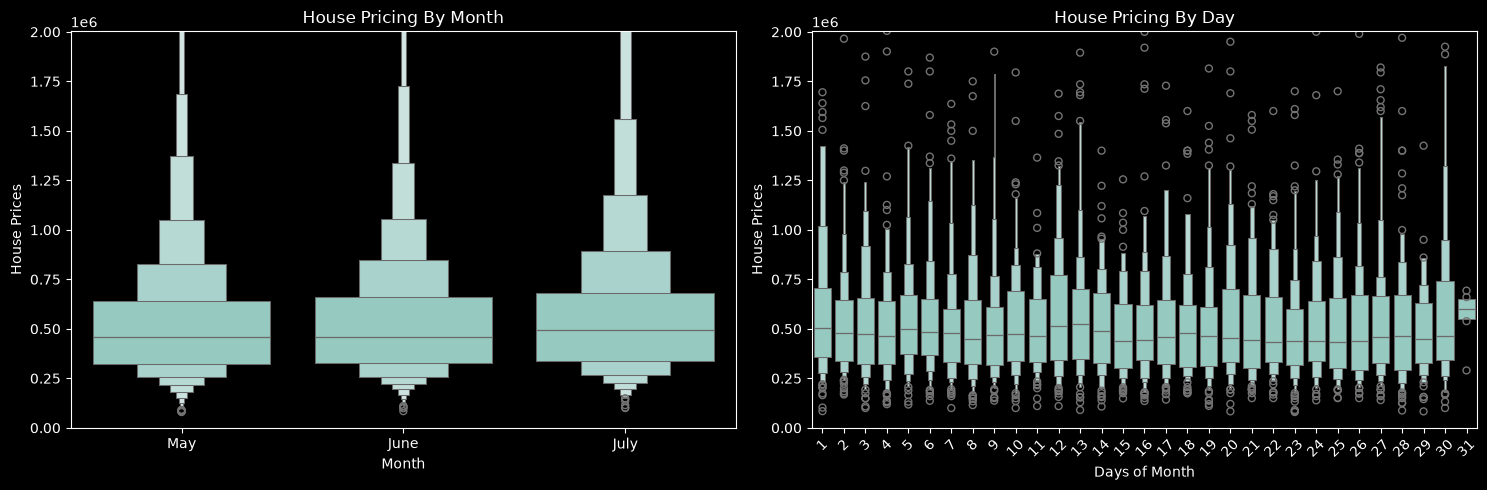

In [155]:
## map the month numbers with there names
df_splited_date_column["month"] = df_splited_date_column["month"].map(
    {
        5: "May",
        6: "June",
        7: "July",
    }
)

## struct the subplots
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

## First plot Month Vs Price
sns.boxenplot(data=df_splited_date_column, x="month", y="price", ax=axes[0])
axes[0].set_title("House Pricing By Month")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("House Prices")


## Second plot Day Vs Price
sns.boxenplot(data=df_splited_date_column, x="day", y="price", ax=axes[1])
axes[1].set_title("House Pricing By Day")
axes[1].set_xlabel("Days of Month")
axes[1].set_ylabel("House Prices")
axes[1].tick_params(axis="x", rotation=45)

"""
## we have outliers values in our data set, so we will quantile it and just 
    take 99% from the values of price 
"""

## apply the quantization
price_limit = df_splited_date_column["price"].quantile(0.99)

## show the new limit
axes[0].set_ylim(0, price_limit)
axes[1].set_ylim(0, price_limit)

## Final Display
plt.tight_layout()
plt.show()

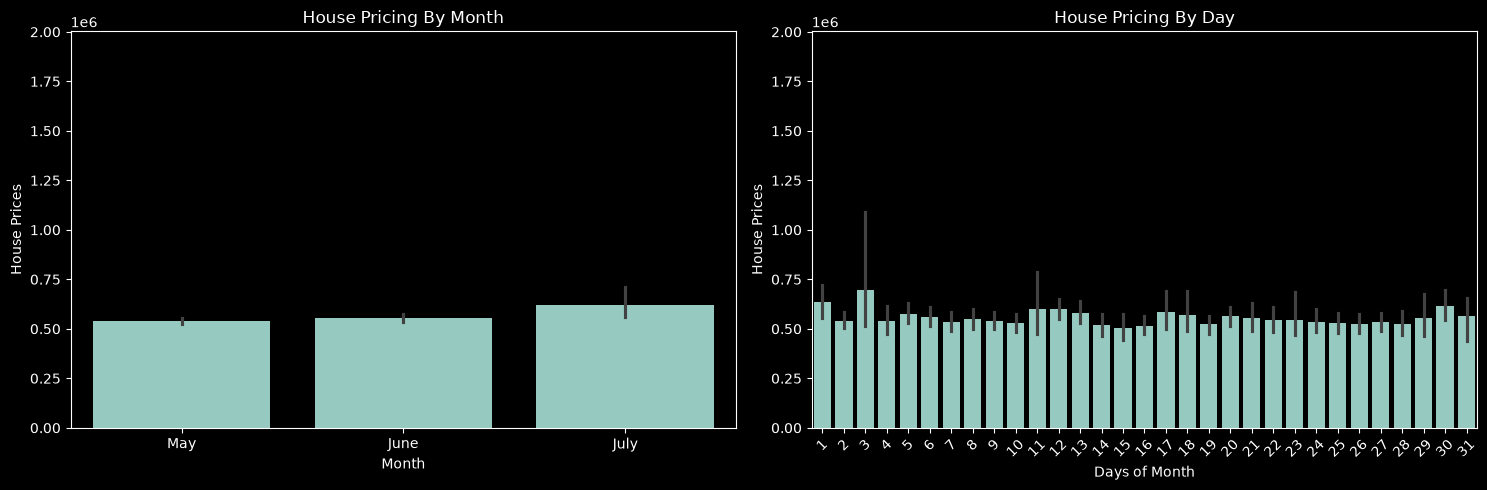

In [156]:
## struct the subplots
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

## First plot Month Vs Price
sns.barplot(data=df_splited_date_column, x="month", y="price", ax=axes[0])
axes[0].set_title("House Pricing By Month")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("House Prices")


## Second plot Day Vs Price
sns.barplot(data=df_splited_date_column, x="day", y="price", ax=axes[1])
axes[1].set_title("House Pricing By Day")
axes[1].set_xlabel("Days of Month")
axes[1].set_ylabel("House Prices")
axes[1].tick_params(axis="x", rotation=45)

"""
## we have outliers values in our data set, so we will quantile it and just 
    take 99% from the values of price 
"""

## apply the quantization
price_limit = df_splited_date_column["price"].quantile(0.99)

## show the new limit
axes[0].set_ylim(0, price_limit)
axes[1].set_ylim(0, price_limit)

## Final Display
plt.tight_layout()
plt.show()

In [157]:
## Calculate the Mean mathimatically

"""
## months -> May, June, July
"""

for i in ("May", "June", "July"):
    sub_data = df_splited_date_column[df_splited_date_column["month"] == i]

    ## calculate the mean of the column
    mean_of_price = sub_data["price"].mean()

    ## Display the final result
    print(f"the mean of prices in {i} -> {mean_of_price:,.2f}")

the mean of prices in May -> 539,179.25
the mean of prices in June -> 554,070.84
the mean of prices in July -> 619,148.62


In [158]:
"""
##There is no strong relationship between house prices and the month or day of sale.
# House prices fluctuate across different months and days without a clear pattern.
# Therefore:
# the date does not appear to be a significant factor in determining house prices.
"""

'\n##There is no strong relationship between house prices and the month or day of sale.\n# House prices fluctuate across different months and days without a clear pattern.\n# Therefore:\n# the date does not appear to be a significant factor in determining house prices.\n'

In [159]:
df.info()

<class 'pandas.DataFrame'>
Index: 4550 entries, 0 to 4599
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           4550 non-null   str    
 1   price          4550 non-null   float64
 2   bedrooms       4550 non-null   float64
 3   bathrooms      4550 non-null   float64
 4   sqft_living    4550 non-null   int64  
 5   sqft_lot       4550 non-null   int64  
 6   floors         4550 non-null   float64
 7   waterfront     4550 non-null   int64  
 8   view           4550 non-null   int64  
 9   condition      4550 non-null   int64  
 10  sqft_above     4550 non-null   int64  
 11  sqft_basement  4550 non-null   int64  
 12  yr_built       4550 non-null   int64  
 13  yr_renovated   4550 non-null   int64  
 14  street         4550 non-null   str    
 15  city           4550 non-null   str    
 16  statezip       4550 non-null   str    
 17  country        4550 non-null   str    
dtypes: float64(4), int64(9),

In [160]:
## the final option we will drop this feature from the main DataFrame
df = df.drop(labels="date", axis=1)

In [161]:
df.info()

<class 'pandas.DataFrame'>
Index: 4550 entries, 0 to 4599
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   price          4550 non-null   float64
 1   bedrooms       4550 non-null   float64
 2   bathrooms      4550 non-null   float64
 3   sqft_living    4550 non-null   int64  
 4   sqft_lot       4550 non-null   int64  
 5   floors         4550 non-null   float64
 6   waterfront     4550 non-null   int64  
 7   view           4550 non-null   int64  
 8   condition      4550 non-null   int64  
 9   sqft_above     4550 non-null   int64  
 10  sqft_basement  4550 non-null   int64  
 11  yr_built       4550 non-null   int64  
 12  yr_renovated   4550 non-null   int64  
 13  street         4550 non-null   str    
 14  city           4550 non-null   str    
 15  statezip       4550 non-null   str    
 16  country        4550 non-null   str    
dtypes: float64(4), int64(9), str(4)
memory usage: 768.9 KB


---


In [162]:
df.columns

Index(['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors',
       'waterfront', 'view', 'condition', 'sqft_above', 'sqft_basement',
       'yr_built', 'yr_renovated', 'street', 'city', 'statezip', 'country'],
      dtype='str')

In [163]:
len(df["street"].unique())

4475

In [164]:
df.shape

(4550, 17)

In [165]:
df["country"].unique()

<StringArray>
['USA']
Length: 1, dtype: str

In [166]:
df["city"].unique()

<StringArray>
[          'Shoreline',             'Seattle',                'Kent',
            'Bellevue',             'Redmond',        'Maple Valley',
          'North Bend',    'Lake Forest Park',           'Sammamish',
              'Auburn',          'Des Moines',             'Bothell',
         'Federal Way',            'Kirkland',            'Issaquah',
         'Woodinville',       'Normandy Park',           'Fall City',
              'Renton',           'Carnation',          'Snoqualmie',
              'Duvall',              'Burien',           'Covington',
 'Inglewood-Finn Hill',             'Kenmore',           'Newcastle',
       'Mercer Island',       'Black Diamond',          'Ravensdale',
          'Clyde Hill',              'Algona',           'Skykomish',
             'Tukwila',              'Vashon',        'Yarrow Point',
              'SeaTac',              'Medina',            'Enumclaw',
     'Snoqualmie Pass',             'Pacific',  'Beaux Arts Village',
      

In [167]:
df["statezip"].unique()

<StringArray>
['WA 98133', 'WA 98119', 'WA 98042', 'WA 98008', 'WA 98052', 'WA 98115',
 'WA 98038', 'WA 98045', 'WA 98155', 'WA 98105', 'WA 98074', 'WA 98106',
 'WA 98007', 'WA 98092', 'WA 98198', 'WA 98006', 'WA 98102', 'WA 98011',
 'WA 98125', 'WA 98003', 'WA 98136', 'WA 98033', 'WA 98029', 'WA 98117',
 'WA 98034', 'WA 98072', 'WA 98023', 'WA 98107', 'WA 98166', 'WA 98116',
 'WA 98024', 'WA 98055', 'WA 98077', 'WA 98027', 'WA 98059', 'WA 98075',
 'WA 98014', 'WA 98065', 'WA 98199', 'WA 98053', 'WA 98058', 'WA 98122',
 'WA 98103', 'WA 98112', 'WA 98005', 'WA 98118', 'WA 98177', 'WA 98004',
 'WA 98019', 'WA 98144', 'WA 98168', 'WA 98001', 'WA 98056', 'WA 98146',
 'WA 98028', 'WA 98148', 'WA 98057', 'WA 98040', 'WA 98010', 'WA 98051',
 'WA 98031', 'WA 98109', 'WA 98030', 'WA 98126', 'WA 98032', 'WA 98178',
 'WA 98288', 'WA 98108', 'WA 98070', 'WA 98188', 'WA 98002', 'WA 98039',
 'WA 98022', 'WA 98068', 'WA 98047', 'WA 98050', 'WA 98354']
Length: 77, dtype: str

In [168]:
"""
## study the relation between all geographical features in the data set
"""

'\n## study the relation between all geographical features in the data set\n'

In [169]:
## separate all geographical feature in separeted dataFrame,
# the main benefit from copy() is to take a separated copy from the dataframe
# with these specific features
geo_data = df[["street", "city", "statezip", "country"]].copy()

In [170]:
"""
## the information about geographical features
# street -> 4525
# city -> 44
# statezip -> 77
# country -> 1
"""

'\n## the information about geographical features\n# street -> 4525\n# city -> 44\n# statezip -> 77\n# country -> 1\n'

In [171]:
## this code will show if there is a city that has more than
# one zip_code

city_zip = pd.crosstab(geo_data["city"], geo_data["statezip"])

print(city_zip)

statezip             WA 98001  WA 98002  WA 98003  WA 98004  WA 98005  \
city                                                                    
Algona                      5         0         0         0         0   
Auburn                     57        35         0         0         0   
Beaux Arts Village          0         0         0         1         0   
Bellevue                    0         0         0        57        29   
Black Diamond               0         0         0         0         0   
Bothell                     0         0         0         0         0   
Burien                      0         0         0         0         0   
Carnation                   0         0         0         0         0   
Clyde Hill                  0         0         0         9         0   
Covington                   0         0         0         0         0   
Des Moines                  0         0         0         0         0   
Duvall                      0         0         0  

In [172]:
"""
## It calculates the frequency of each combination between the two variables,
# rather than measuring the strength of the statistical relationship between them.
"""

'\n## It calculates the frequency of each combination between the two variables,\n# rather than measuring the strength of the statistical relationship between them.\n'

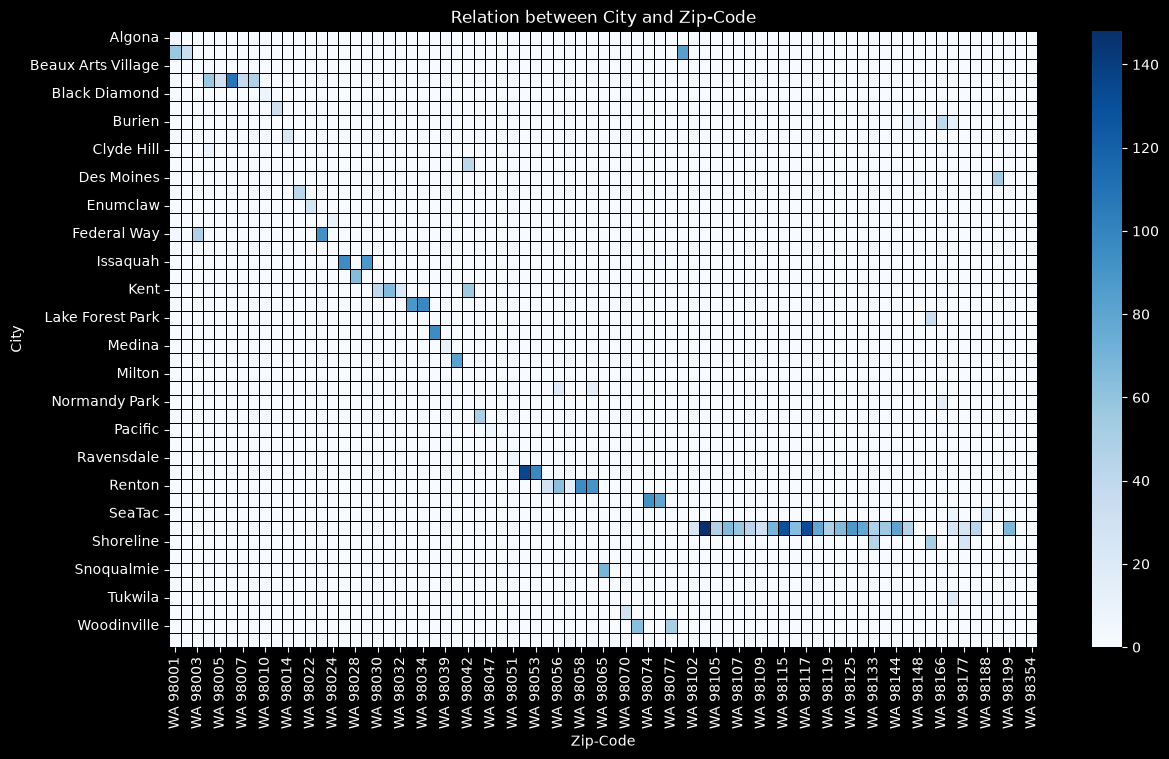

In [173]:
## visualisation part

plt.figure(figsize=(14, 8))
sns.heatmap(city_zip, cmap="Blues", linewidths=0.5, linecolor="black")
plt.title("Relation between City and Zip-Code")
plt.xlabel("Zip-Code")
plt.ylabel("City")


## finally the display
plt.show()

In [174]:
## Calculate the Mean for the prices for each city and return back
# the min mean value for prices and also the max mean value

print(
    f"the min mean of all prices for all cities -> {df.groupby("city")['price'].mean().min():.2f}"
)
print(
    f"the max mean of all prices for all cities -> {df.groupby("city")['price'].mean().max():.2f}"
)

the min mean of all prices for all cities -> 207288.00
the max mean of all prices for all cities -> 2046559.09


/var/folders/rz/yjjy4tvj2gng41k4v004lbtc0000gn/T/ipykernel_8745/3345672050.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=city_prices.index, y=city_prices.values, palette="viridis")


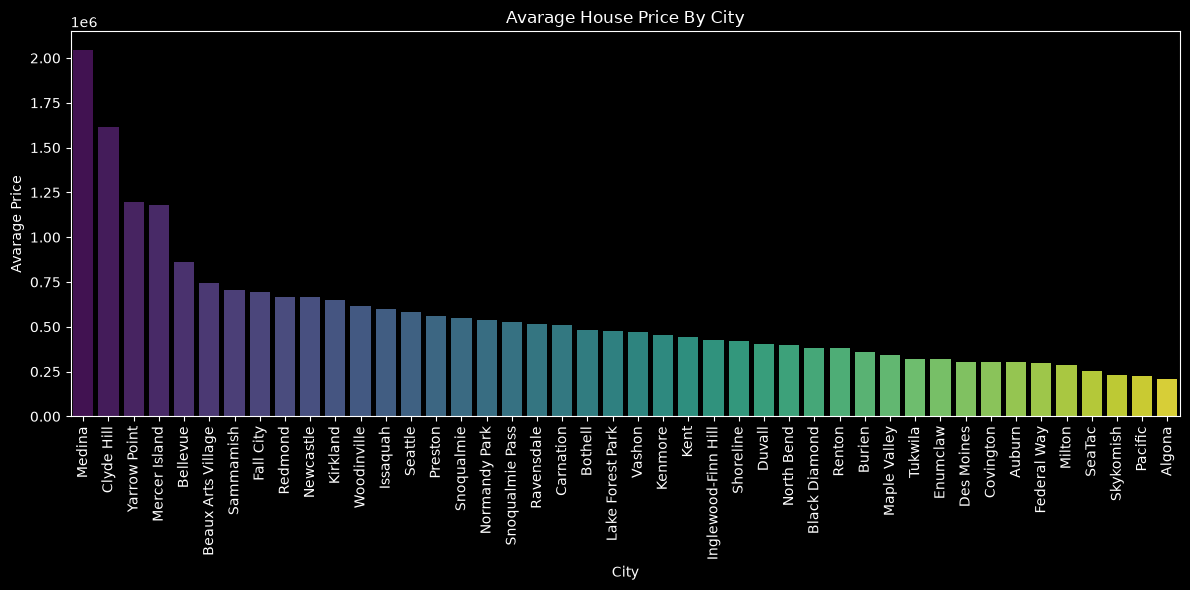

In [175]:
## Visualize the calculation

## Calculate the Mean and sort all values in Discending Order
city_prices = df.groupby("city")["price"].mean().sort_values(ascending=False)

## Drow the barplot with seaborn
plt.figure(figsize=(12, 6))
sns.barplot(x=city_prices.index, y=city_prices.values, palette="viridis")
plt.xticks(rotation=90)
plt.title("Avarage House Price By City")
plt.xlabel("City")
plt.ylabel("Avarage Price")
plt.tight_layout()
plt.show()

In [176]:
"""
## So the result that displied in the barplot is:
# Medina -> is the Largest Avarage
# Algona -> is the Smallest Avarage
"""

'\n## So the result that displied in the barplot is:\n# Medina -> is the Largest Avarage\n# Algona -> is the Smallest Avarage\n'

/var/folders/rz/yjjy4tvj2gng41k4v004lbtc0000gn/T/ipykernel_8745/3340978447.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(data=df, x="city", y="price", palette="Set2")


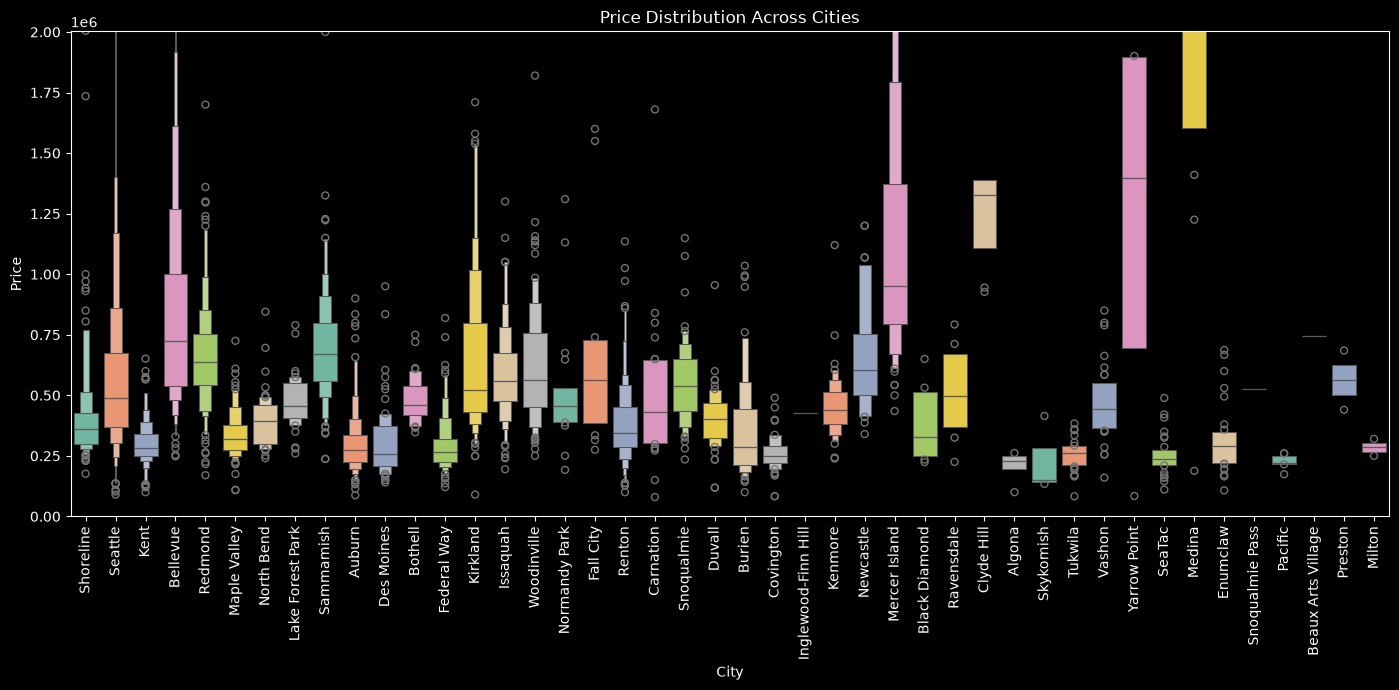

In [177]:
## Boxplot Visualisation

plt.figure(figsize=(14, 7))

## Important note:
# we will use price_limit variable that we calculate before to avoid the
# hight values of price
sns.boxenplot(data=df, x="city", y="price", palette="Set2")
plt.title("Price Distribution Across Cities")
plt.xlabel("City")
plt.ylabel("Price")
plt.xticks(rotation=90)
plt.tight_layout()

## show the new limit
plt.ylim(0, price_limit)
plt.ylim(0, price_limit)

plt.show()

In [178]:
df.columns

Index(['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors',
       'waterfront', 'view', 'condition', 'sqft_above', 'sqft_basement',
       'yr_built', 'yr_renovated', 'street', 'city', 'statezip', 'country'],
      dtype='str')

In [179]:
df[["city", "statezip", "street"]].dtypes

city        str
statezip    str
street      str
dtype: object

In [180]:
df["country"].unique()

<StringArray>
['USA']
Length: 1, dtype: str

In [181]:
"""
## The final Report for the Geographical Features:
# Country Feature: This value is useless and also won't add any thing
# to our model while training, that because it has only single value ('USA')
# and there is no variance between different instances in the dataset, So -> ('Will be removed')

# Street Feature: This Feature is not useless, but it has one problem,
# the type of this feature is ('str'), that often means we will need to use
# Encoding with it, the problem is here, the number of unique values in this feature
# is to larg, so if we used OneHotEncoder will cause Feature Explosion, and also if we
# used LabelEncoder we will get high value and that will distripute
# out model while training, So -> ('Will be Removed')

# city and statezip: These Features are so important and will help our model
# while training, that because they have a strong relation with the target,
# So -> ('Will be processed by LableEncoder'), the reason for not using OneHotEncoder:
# because these two features have more unique values, that will cause Feature Explosion
"""

"\n## The final Report for the Geographical Features:\n# Country Feature: This value is useless and also won't add any thing\n# to our model while training, that because it has only single value ('USA')\n# and there is no variance between different instances in the dataset, So -> ('Will be removed')\n\n# Street Feature: This Feature is not useless, but it has one problem,\n# the type of this feature is ('str'), that often means we will need to use\n# Encoding with it, the problem is here, the number of unique values in this feature\n# is to larg, so if we used OneHotEncoder will cause Feature Explosion, and also if we\n# used LabelEncoder we will get high value and that will distripute\n# out model while training, So -> ('Will be Removed')\n\n# city and statezip: These Features are so important and will help our model\n# while training, that because they have a strong relation with the target,\n# So -> ('Will be processed by LableEncoder'), the reason for not using OneHotEncoder:\n# be

In [182]:
df = df.drop(labels=["country", "street"], axis=1)

In [183]:
df.info()

<class 'pandas.DataFrame'>
Index: 4550 entries, 0 to 4599
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   price          4550 non-null   float64
 1   bedrooms       4550 non-null   float64
 2   bathrooms      4550 non-null   float64
 3   sqft_living    4550 non-null   int64  
 4   sqft_lot       4550 non-null   int64  
 5   floors         4550 non-null   float64
 6   waterfront     4550 non-null   int64  
 7   view           4550 non-null   int64  
 8   condition      4550 non-null   int64  
 9   sqft_above     4550 non-null   int64  
 10  sqft_basement  4550 non-null   int64  
 11  yr_built       4550 non-null   int64  
 12  yr_renovated   4550 non-null   int64  
 13  city           4550 non-null   str    
 14  statezip       4550 non-null   str    
dtypes: float64(4), int64(9), str(2)
memory usage: 697.8 KB


---


In [184]:
df[["bedrooms", "bathrooms", "floors"]].head(20)

,bedrooms,bathrooms,floors
0,3.0,1.50,1.5
1,5.0,2.50,2.0
2,3.0,2.00,1.0
3,3.0,2.25,1.0
4,4.0,2.50,1.0
5,2.0,1.00,1.0
6,2.0,2.00,1.0
7,4.0,2.50,2.0
8,3.0,2.50,1.0
9,4.0,2.00,1.5


In [185]:
"""
## This is just a check, to see if there are any complete decimal number like that
# (1.2, 4.4, ...) or just a float numbers without decimal numbers (1.0, 2.0 ,....).
"""

'\n## This is just a check, to see if there are any complete decimal number like that\n# (1.2, 4.4, ...) or just a float numbers without decimal numbers (1.0, 2.0 ,....).\n'

In [186]:
df[(df["floors"] > 0.0) & (df["floors"] < 1.0)]

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,city,statezip


In [187]:
df[(df["bedrooms"] > 0.0) & (df["bedrooms"] < 1.0)]

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,city,statezip


In [188]:
len(df[(df["bathrooms"] > 0.0) & (df["bathrooms"] < 1.0)])

17

In [189]:
## Display some statistics for ('bedrooms', 'bathrooms', 'floors') features

print("-" * 35)
print(f"the min value in bedrooms -> {df['bedrooms'].min()}")
print(f"the max value in bedrooms -> {df['bedrooms'].max()}")
print("-" * 35)
print(f"the min value in bathrooms -> {df['bathrooms'].min()}")
print(f"the max value in bathrooms -> {df['bathrooms'].max()}")
print("-" * 35)
print(f"the min value in floors -> {df['floors'].min()}")
print(f"the max value in floors -> {df['floors'].max()}")
print("-" * 35)

-----------------------------------
the min value in bedrooms -> 0.0
the max value in bedrooms -> 9.0
-----------------------------------
the min value in bathrooms -> 0.0
the max value in bathrooms -> 8.0
-----------------------------------
the min value in floors -> 1.0
the max value in floors -> 3.5
-----------------------------------


In [190]:
"""
## The final report about these features ('bedrooms', 'bathrooms', 'floors'):
# bedrooms and floors -> the dtype of these features is ('float'), but this is no problem,
# because there is no realy decimal values in these features at any instance in the dataset
# So -> ('The solution is just converting it into ('int') dtype while preprocessing)

# bathrooms -> this feature also has the same problem, but this time, there is realy decimal
# values at 17 instance in the dataset, but it doesn't make any problem, that because, these
# number can be refering to different sizes of bathrooms at the home.
"""

"\n## The final report about these features ('bedrooms', 'bathrooms', 'floors'):\n# bedrooms and floors -> the dtype of these features is ('float'), but this is no problem,\n# because there is no realy decimal values in these features at any instance in the dataset\n# So -> ('The solution is just converting it into ('int') dtype while preprocessing)\n\n# bathrooms -> this feature also has the same problem, but this time, there is realy decimal\n# values at 17 instance in the dataset, but it doesn't make any problem, that because, these\n# number can be refering to different sizes of bathrooms at the home.\n"

---


In [191]:
df.info()

<class 'pandas.DataFrame'>
Index: 4550 entries, 0 to 4599
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   price          4550 non-null   float64
 1   bedrooms       4550 non-null   float64
 2   bathrooms      4550 non-null   float64
 3   sqft_living    4550 non-null   int64  
 4   sqft_lot       4550 non-null   int64  
 5   floors         4550 non-null   float64
 6   waterfront     4550 non-null   int64  
 7   view           4550 non-null   int64  
 8   condition      4550 non-null   int64  
 9   sqft_above     4550 non-null   int64  
 10  sqft_basement  4550 non-null   int64  
 11  yr_built       4550 non-null   int64  
 12  yr_renovated   4550 non-null   int64  
 13  city           4550 non-null   str    
 14  statezip       4550 non-null   str    
dtypes: float64(4), int64(9), str(2)
memory usage: 697.8 KB


In [192]:
## simple check on Condition Feature

df["condition"].unique(), df["condition"].dtypes

(array([3, 5, 4, 2, 1]), dtype('int64'))

In [193]:
## display the mean of each rate

mean_for_1_and_2 = df[df["condition"] < 3]
mean_for_3 = df[df["condition"] == 3]
mean_for_4_and_5 = df[df["condition"] > 3]


## display the final results
print(f"the mean for 1 and 2 -> {mean_for_1_and_2['price'].mean():.2f}")
print(f"the mean for 3 -> {mean_for_3['price'].mean():.2f}")
print(f"the mean for 4 and 5 -> {mean_for_4_and_5['price'].mean():.2f}")

the mean for 1 and 2 -> 339221.11
the mean for 3 -> 554742.41
the mean for 4 and 5 -> 568394.09


---


In [194]:
df.info()

<class 'pandas.DataFrame'>
Index: 4550 entries, 0 to 4599
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   price          4550 non-null   float64
 1   bedrooms       4550 non-null   float64
 2   bathrooms      4550 non-null   float64
 3   sqft_living    4550 non-null   int64  
 4   sqft_lot       4550 non-null   int64  
 5   floors         4550 non-null   float64
 6   waterfront     4550 non-null   int64  
 7   view           4550 non-null   int64  
 8   condition      4550 non-null   int64  
 9   sqft_above     4550 non-null   int64  
 10  sqft_basement  4550 non-null   int64  
 11  yr_built       4550 non-null   int64  
 12  yr_renovated   4550 non-null   int64  
 13  city           4550 non-null   str    
 14  statezip       4550 non-null   str    
dtypes: float64(4), int64(9), str(2)
memory usage: 697.8 KB


In [195]:
df["yr_built"].unique()

array([1955, 1921, 1966, 1963, 1976, 1938, 1989, 1985, 1945, 1948, 1909,
       1980, 1939, 1965, 1956, 1997, 1987, 1983, 1923, 1954, 2005, 1991,
       1959, 1920, 1979, 1951, 1967, 2004, 2014, 1995, 1944, 1992, 1957,
       1978, 1974, 1950, 1990, 1949, 1968, 1977, 1996, 2001, 2000, 1929,
       2006, 2008, 2009, 2012, 2013, 2007, 1986, 1973, 1988, 1900, 1928,
       1982, 1960, 2003, 1998, 1942, 1908, 1958, 1971, 1975, 1961, 1924,
       1902, 1962, 1953, 1999, 1994, 1930, 1984, 2010, 1912, 1947, 1916,
       1940, 1970, 1952, 1964, 1926, 1905, 1969, 1903, 1943, 1993, 1946,
       1910, 1904, 1981, 1906, 1922, 2011, 2002, 1917, 1913, 1914, 1937,
       1925, 1932, 1918, 1972, 1941, 1919, 1936, 1911, 1927, 1931, 1901,
       1907, 1915, 1935, 1933, 1934])

In [196]:
df["yr_renovated"].unique()

array([2005,    0, 1992, 1994, 2010, 1988, 2009, 1969, 2000, 1979, 1989,
       2014, 1999, 2003, 1983, 1997, 1912, 1923, 1954, 2011, 2001, 2013,
       2006, 1972, 1985, 1998, 2004, 1958, 2008, 1970, 1982, 1986, 1996,
       2002, 1971, 1990, 1956, 1945, 1984, 2012, 1993, 2007, 1981, 1974,
       1963, 1968, 1995, 1934, 1953, 1966, 1955, 1987, 1960, 1978, 1980,
       1948, 1991, 1913, 1977])

### **_`PreProcessing`_**


In [197]:
## first we will convert the datatype of (bedrooms and floors features):

df["bedrooms"] = df["bedrooms"].astype(int)
df["floors"] = df["floors"].astype(int)

print(f"the types now -> {df[['bedrooms', 'floors']].dtypes}")

the types now -> bedrooms    int64
floors      int64
dtype: object


In [198]:
df["city"] = df["city"].astype(object)
df["statezip"] = df["statezip"].astype(object)

print(f"the types now -> {df[['city', 'statezip']].dtypes}")

the types now -> city        object
statezip    object
dtype: object


In [199]:
## Splite features

X = df.drop(labels="price", axis=1)
Y = df["price"]

x_train, x_test, y_train, y_test = train_test_split(
    X, Y, shuffle=True, test_size=0.3, random_state=34
)

## make sure all thing is splited correctly
print("-" * 30)
print(f"split for x_train -> {x_train.shape}")
print("-" * 30)
print(f"split for x_test -> {x_test.shape}")
print("-" * 30)
print(f"split for y_train -> {y_train.shape}")
print("-" * 30)
print(f"split for y_test -> {y_test.shape}")
print("-" * 30)

------------------------------
split for x_train -> (3185, 14)
------------------------------
split for x_test -> (1365, 14)
------------------------------
split for y_train -> (3185,)
------------------------------
split for y_test -> (1365,)
------------------------------


In [200]:
df.describe()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated
count,4.550000e+03,4550.000000,4550.000000,4550.000000,4.550000e+03,4550.000000,4550.000000,4550.000000,4550.000000,4550.000000,4550.000000,4550.000000,4550.000000
mean,5.580268e+05,3.394945,2.155275,2132.669451,1.483495e+04,1.459341,0.006593,0.234725,3.449890,1822.450769,310.218681,1970.801978,808.741758
std,5.639329e+05,0.904458,0.776248,955.844442,3.596802e+04,0.552374,0.080941,0.765449,0.674257,854.407044,462.015516,29.760281,979.455754
min,8.000000e+04,0.000000,0.000000,370.000000,6.380000e+02,1.000000,0.000000,0.000000,1.000000,370.000000,0.000000,1900.000000,0.000000
25%,3.264464e+05,3.000000,1.750000,1460.000000,5.000000e+03,1.000000,0.000000,0.000000,3.000000,1190.000000,0.000000,1951.000000,0.000000
50%,4.650000e+05,3.000000,2.250000,1970.000000,7.680000e+03,1.000000,0.000000,0.000000,3.000000,1590.000000,0.000000,1976.000000,0.000000
75%,6.575000e+05,4.000000,2.500000,2610.000000,1.096800e+04,2.000000,0.000000,0.000000,4.000000,2300.000000,600.000000,1997.000000,1999.000000
max,2.659000e+07,9.000000,8.000000,13540.000000,1.074218e+06,3.000000,1.000000,4.000000,5.000000,9410.000000,4820.000000,2014.000000,2014.000000


In [201]:
df["waterfront"].unique()

array([0, 1])

In [202]:
df.info()

<class 'pandas.DataFrame'>
Index: 4550 entries, 0 to 4599
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   price          4550 non-null   float64
 1   bedrooms       4550 non-null   int64  
 2   bathrooms      4550 non-null   float64
 3   sqft_living    4550 non-null   int64  
 4   sqft_lot       4550 non-null   int64  
 5   floors         4550 non-null   int64  
 6   waterfront     4550 non-null   int64  
 7   view           4550 non-null   int64  
 8   condition      4550 non-null   int64  
 9   sqft_above     4550 non-null   int64  
 10  sqft_basement  4550 non-null   int64  
 11  yr_built       4550 non-null   int64  
 12  yr_renovated   4550 non-null   int64  
 13  city           4550 non-null   object 
 14  statezip       4550 non-null   object 
dtypes: float64(2), int64(11), object(2)
memory usage: 697.8+ KB


In [203]:
## splite our features into : ('num_feature', 'cat_feature', 'ready_feature')

## Extract Ready Features
ready_feature = ["waterfront"]

## Extract Numirical Features
num_features = [
    i
    for i in df.columns
    if df[i].dtypes != "object" and i not in ready_feature and i != "price"
]

## Extract Categorical Features
cat_features = [i for i in df.columns if df[i].dtypes == "object"]


## display the final results
print("-" * 200)
print(f"Ready Features -> {ready_feature}, \n the lenght of list{len(ready_feature)}")
print("-" * 200)
print(f"Numirical Features -> {num_features}, \n the lenght of list{len(num_features)}")
print("-" * 200)
print(
    f"Categorical Features -> {cat_features}, \n the lenght of list{len(cat_features)}"
)
print("-" * 200)

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
Ready Features -> ['waterfront'], 
 the lenght of list1
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
Numirical Features -> ['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'view', 'condition', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated'], 
 the lenght of list11
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
Categorical Features -> ['city', 'statezip'], 
 the lenght of list2
------------------------------------------------------------------------------------

### **_`PipeLines`_**


In [204]:
## Create Pipeline for Ready, Num, Cat features

## Pipeline for Ready Features
ready_pipeline = Pipeline(
    steps=[
        ("imputing", SimpleImputer()),
    ]
)

## Pipeline for Num Features
num_pipeline = Pipeline(
    steps=[
        ("imputing", SimpleImputer()),
        ("scaling", StandardScaler()),
    ]
)

## Pipeline for Cat Features
cat_pipeline = Pipeline(
    steps=[
        ("imputing", SimpleImputer(strategy="most_frequent")),
        (
            "label_encoder",
            OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
        ),
        ("scaling", StandardScaler()),
    ]
)

"""
## The main reason for not using LabelEncoder on training data is: 
# LabelEncoder work only on 1D array, and the training data is 2D
# So -> the best obtion rather than using LabelEncoder is OrdinalEncoder or OneHotEncoder
# but the other reason for not using OneHotEncoder is we have more unique values in the 
# categorical features that will be Encoded. 
"""


## Compine all Pipelines
processors = ColumnTransformer(
    transformers=[
        ("ready_feature", ready_pipeline, ready_feature),
        ("num_features", num_pipeline, num_features),
        ("cat_features", cat_pipeline, cat_features),
    ]
)

In [205]:
### Apply preprocessing Opeartions

## Apply transformation on Training Data
x_train_final = processors.fit_transform(x_train)

## App;y tranformation on Testing Data
x_test_final = processors.transform(x_test)

In [206]:
## Dump the processors

## Create the utils path
UTILS_DIR = os.path.join(MAIN_PATH, "..", "utils")

## create the directory
os.makedirs(UTILS_DIR, exist_ok=True)

## create the list that will save the processors
PROCESSOR_PATH = os.path.join(UTILS_DIR, "processors.pkl")

## dump the processors
joblib.dump(processors, PROCESSOR_PATH)

print("Preprocessor saved successfully! ✅")

Preprocessor saved successfully! ✅


### **_`Training Models`_**


In [207]:
### Training LinearRegression model

linear_reg = LinearRegression(n_jobs=-1)

## train the model
linear_reg.fit(x_train_final, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",-1
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](14,)","[581452.41,-56562.09, 73631. ,..., 6332.75, 34339.69,-23665.72]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,5.574e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,14
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(13)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](14,)","[111.21, 81.24, 72.36,..., 26.75, 4.35, 0. ]"


In [208]:
## Model Evaluation

y_predict = linear_reg.predict(x_test_final)

### check the model performance

## 1. mean_squared_error
mse = mean_squared_error(y_test, y_predict)

## 2. mean_absolute_error
mae = mean_absolute_error(y_test, y_predict)

## 3. r2_score
r2 = r2_score(y_test, y_predict)

## show the final results
print("-" * 40)
print(f"Mean Squared Error -> {mse:.2f}")
print("-" * 40)
print(f"Mean Absolute Error -> {mae:.2f}")
print("-" * 40)
print(f"R2 Score -> {r2:.2f}")
print("-" * 40)

----------------------------------------
Mean Squared Error -> 60892711145.97
----------------------------------------
Mean Absolute Error -> 159442.25
----------------------------------------
R2 Score -> 0.50
----------------------------------------


In [209]:
### RandomForestRegressor

## initiate the model
random_forest_reg = RandomForestRegressor(
    n_estimators=30,
    max_depth=10,
    n_jobs=-1,
    random_state=32,
)

## train the model
random_forest_reg.fit(x_train_final, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",30
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",32
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_

In [210]:
## Model Evaluation

y_predict = random_forest_reg.predict(x_test_final)

## Check the model performance

## 1. mean_squared_error
mse = mean_squared_error(y_test, y_predict)

## 2. mean_absolute_error
mae = mean_absolute_error(y_test, y_predict)

## 3. r2_score
r2 = r2_score(y_test, y_predict)

## show the final results
print("-" * 40)
print(f"Mean Squared Error -> {mse:.2f}")
print("-" * 40)
print(f"Mean Absolute Error -> {mae:.2f}")
print("-" * 40)
print(f"R2 Score -> {r2:.2f}")
print("-" * 40)

----------------------------------------
Mean Squared Error -> 70815607534.55
----------------------------------------
Mean Absolute Error -> 137252.52
----------------------------------------
R2 Score -> 0.42
----------------------------------------


### **_`Fixing The Problem`_**


In [211]:
"""
## Check if there are any outliers in the Target Column
"""

'\n## Check if there are any outliers in the Target Column\n'

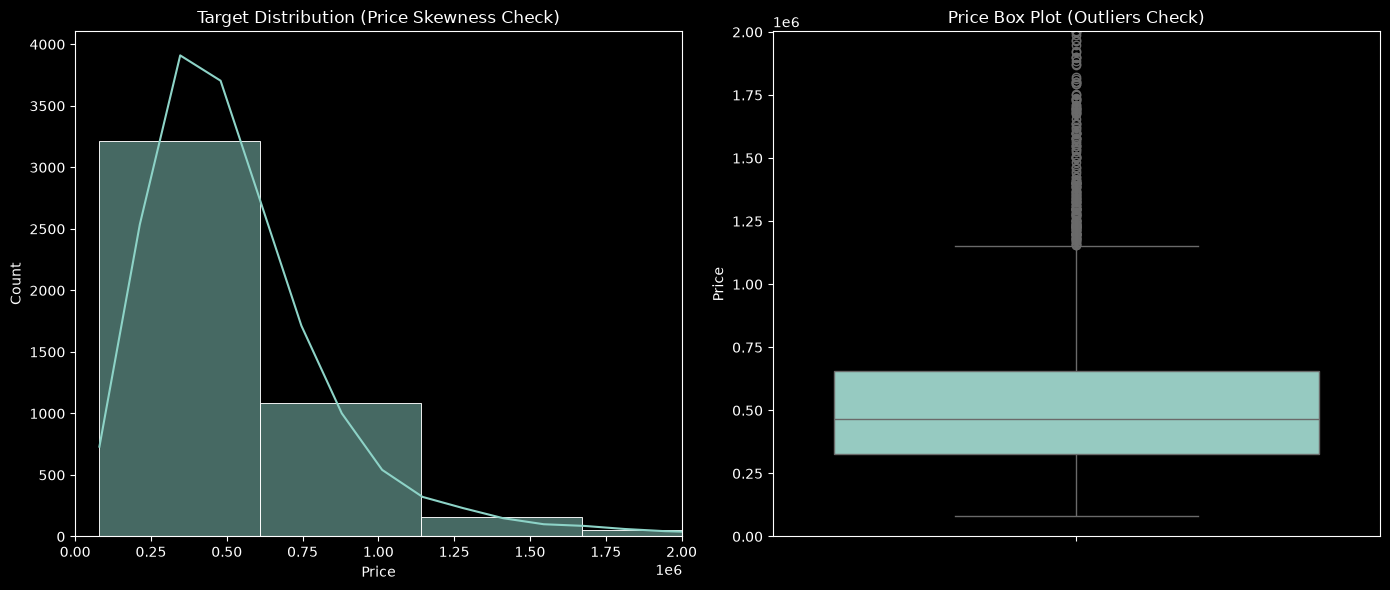

In [212]:
plt.figure(figsize=(14, 6))


plt.subplot(1, 2, 1)
sns.histplot(df["price"], kde=True, bins=50)
plt.title("Target Distribution (Price Skewness Check)")
plt.xlabel("Price")
plt.ylabel("Count")
plt.xlim(0, price_limit)


plt.subplot(1, 2, 2)
sns.boxplot(y=df["price"])
plt.title("Price Box Plot (Outliers Check)")
plt.ylabel("Price")
plt.ylim(0, price_limit)

plt.tight_layout()
plt.show()

In [213]:
"""
## The final report:
# The Histogram shows that there is Right-Skewed in the target values
# And the Boxplot shows also that there are outliers values in the target
# So -> ('we will try np.log (the Logarithm Algorithm from numpy)')
"""

"\n## The final report:\n# The Histogram shows that there is Right-Skewed in the target values\n# And the Boxplot shows also that there are outliers values in the target\n# So -> ('we will try np.log (the Logarithm Algorithm from numpy)')\n"

In [214]:
## apply transformation on the target
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

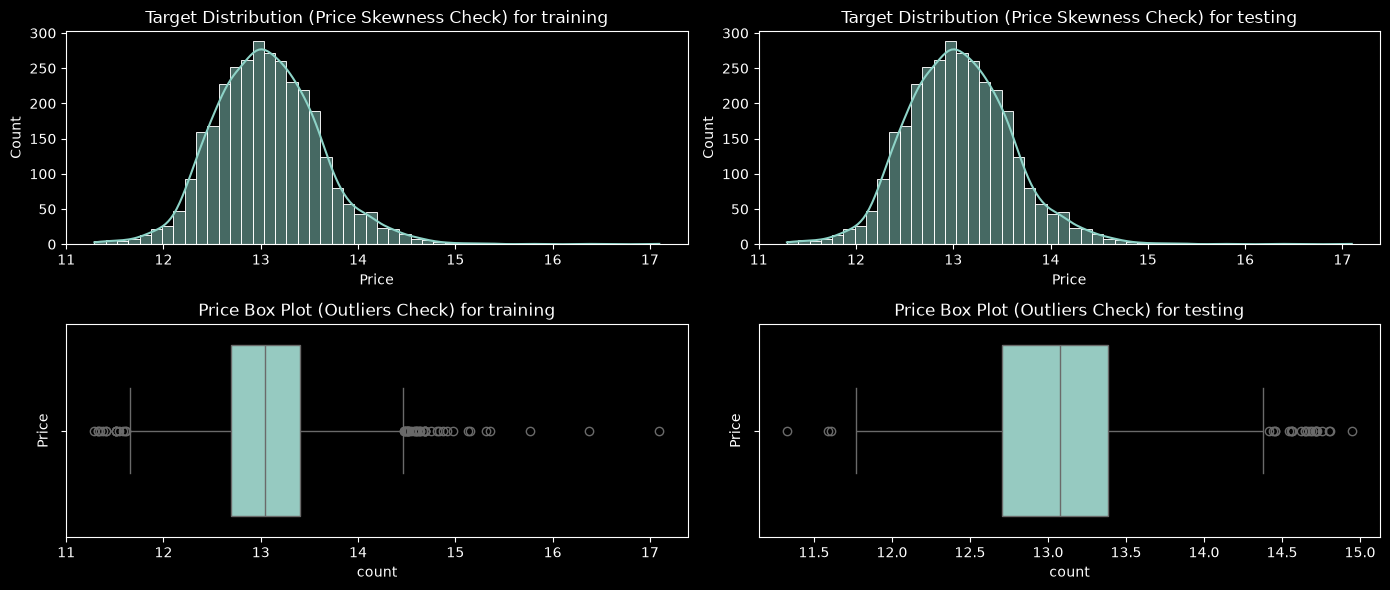

In [215]:
## Check the Right-Skewed again

plt.figure(figsize=(14, 6))


plt.subplot(2, 2, 1)
sns.histplot(y_train_log, kde=True, bins=50)
plt.title("Target Distribution (Price Skewness Check) for training")
plt.xlabel("Price")
plt.ylabel("Count")


plt.subplot(2, 2, 2)
sns.histplot(y_train_log, kde=True, bins=50)
plt.title("Target Distribution (Price Skewness Check) for testing")
plt.xlabel("Price")
plt.ylabel("Count")


plt.subplot(2, 2, 3)
sns.boxplot(x=y_train_log)
plt.title("Price Box Plot (Outliers Check) for training")
plt.xlabel("count")
plt.ylabel("Price")


plt.subplot(2, 2, 4)
sns.boxplot(x=y_test_log)
plt.title("Price Box Plot (Outliers Check) for testing")
plt.xlabel("count")
plt.ylabel("Price")


plt.tight_layout()
plt.show()

In [216]:
"""
Inverse Transformation Step (Log Scale -> Original Price Scale):
----------------------------------------------------------------
1. Why we do this:
   The model was trained on log-transformed target values (`np.log1p(price)`) to handle
   right-skewness. Therefore, `model.predict()` outputs predictions in log scale (e.g., ~13.0),
   not actual dollar amounts.

2. How it works:
   We apply `np.expm1()` (the exact inverse of `np.log1p()`) to convert the predicted
   log values back into real currency values before calculating evaluation metrics
   (MAE, RMSE, R2) against the original `y_test`.

3. Production / Inference Reminder:
   Always apply `np.expm1()` on the model's raw output when predicting prices for new,
   unseen houses in deployment.
"""

"\nInverse Transformation Step (Log Scale -> Original Price Scale):\n----------------------------------------------------------------\n1. Why we do this:\n   The model was trained on log-transformed target values (`np.log1p(price)`) to handle\n   right-skewness. Therefore, `model.predict()` outputs predictions in log scale (e.g., ~13.0),\n   not actual dollar amounts.\n\n2. How it works:\n   We apply `np.expm1()` (the exact inverse of `np.log1p()`) to convert the predicted\n   log values back into real currency values before calculating evaluation metrics\n   (MAE, RMSE, R2) against the original `y_test`.\n\n3. Production / Inference Reminder:\n   Always apply `np.expm1()` on the model's raw output when predicting prices for new,\n   unseen houses in deployment.\n"

### **_`Re Train our models agian`_**


In [217]:
## LinearRegression
linear_reg.fit(x_train_final, y_train_log)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",-1
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](14,)","[ 0.2 ,-0.04, 0.11,..., 0. , 0.11,-0.05]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,13.06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,14
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(13)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](14,)","[111.21, 81.24, 72.36,..., 26.75, 4.35, 0. ]"


In [218]:
## Model Evaluation
y_predict = linear_reg.predict(x_test_final)

## Check the model performance

## 1. mean_squared_error
mse = mean_squared_error(y_test_log, y_predict)

## 2. mean_absolute_error
mae = mean_absolute_error(y_test_log, y_predict)

## 3. r2_score
r2 = r2_score(y_test_log, y_predict)

## show the final results
print("-" * 40)
print(f"Mean Squared Error -> {mse:.2f}")
print("-" * 40)
print(f"Mean Absolute Error -> {mae:.2f}")
print("-" * 40)
print(f"R2 Score -> {r2:.2f}")
print("-" * 40)

----------------------------------------
Mean Squared Error -> 0.13
----------------------------------------
Mean Absolute Error -> 0.28
----------------------------------------
R2 Score -> 0.53
----------------------------------------


In [219]:
## RandomForestRegressor
random_forest_reg.fit(x_train_final, y_train_log)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",30
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",32
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_

In [220]:
## Model Evaluation
y_predict = random_forest_reg.predict(x_test_final)

## Check the model performance

## 1. mean_squared_error
mse = mean_squared_error(y_test_log, y_predict)

## 2. mean_absolute_error
mae = mean_absolute_error(y_test_log, y_predict)

## 3. r2_score
r2 = r2_score(y_test_log, y_predict)

## show the final results
print("-" * 40)
print(f"Mean Squared Error -> {mse:.2f}")
print("-" * 40)
print(f"Mean Absolute Error -> {mae:.2f}")
print("-" * 40)
print(f"R2 Score -> {r2:.2f}")
print("-" * 40)

----------------------------------------
Mean Squared Error -> 0.08
----------------------------------------
Mean Absolute Error -> 0.20
----------------------------------------
R2 Score -> 0.70
----------------------------------------


### **_`HyperParameters Tuning`_**


In [221]:
## initiate the model object
random_forest_reg = RandomForestRegressor(random_state=32)

## parameters for compination
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 15, 25, 35],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
}


## apply GridSearchCV
random_forest_grid_search = GridSearchCV(
    estimator=random_forest_reg,
    param_grid=param_grid,
    cv=3,
    scoring="r2",
    n_jobs=-1,
)

## train the model
random_forest_grid_search.fit(x_train_final, y_train_log)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=32)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 15, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], 'n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,

In [222]:
## Model Evaluation
y_predict = random_forest_grid_search.predict(x_test_final)

## Check the model performance

## 1. mean_squared_error
mse = mean_squared_error(y_test_log, y_predict)

## 2. mean_absolute_error
mae = mean_absolute_error(y_test_log, y_predict)

## 3. r2_score
r2 = r2_score(y_test_log, y_predict)

## show the final results
print("-" * 40)
print(f"Mean Squared Error -> {mse:.2f}")
print("-" * 40)
print(f"Mean Absolute Error -> {mae:.2f}")
print("-" * 40)
print(f"R2 Score -> {r2:.2f}")
print("-" * 40)

----------------------------------------
Mean Squared Error -> 0.08
----------------------------------------
Mean Absolute Error -> 0.19
----------------------------------------
R2 Score -> 0.73
----------------------------------------


In [225]:
## Save Randome Forest

MODEL_PATH = os.path.join(UTILS_DIR, "Random_forest_grid_model.pkl")

joblib.dump(random_forest_grid_search, MODEL_PATH)

print("Preprocessor saved successfully! ✅")

Preprocessor saved successfully! ✅


In [224]:
## Model Evaluation

y_predict_train = random_forest_grid_search.predict(x_train_final)
y_predict_test = random_forest_grid_search.predict(x_test_final)

train_mae = mean_absolute_error(y_train_log, y_predict_train)
test_mae = mean_absolute_error(y_test_log, y_predict_test)

train_rmse = np.sqrt(mean_squared_error(y_train_log, y_predict_train))
test_rmse = np.sqrt(mean_squared_error(y_test_log, y_predict_test))

train_r2 = r2_score(y_train_log, y_predict_train)
test_r2 = r2_score(y_test_log, y_predict_test)

print(f"Training MAE (log scale): {train_mae:.4f}")
print(f"Testing MAE (log scale): {test_mae:.4f}")
print(f"Training RMSE (log scale): {train_rmse:.4f}")
print(f"Testing RMSE (log scale): {test_rmse:.4f}")
print(f"Training R²: {train_r2:.4f}")
print(f"Testing R²: {test_r2:.4f}")


Training MAE (log scale): 0.0880
Testing MAE (log scale): 0.1853
Training RMSE (log scale): 0.1440
Testing RMSE (log scale): 0.2744
Training R²: 0.9301
Testing R²: 0.7287
